# Домашна работа по МУ 2025/26

Предвидување дали индустриски клиенти на компанија за одржување ќе ја напуштат компанијата и ќе ги откажат услугите.

Потребно е да се направи модел за предвидување на тоа кои клиенти (индустриски компании) на една компанија за одржување на индустриска опрема би ја напуштиле компанијата и би го раскинале договорот. Ова се прави со цел компанијата да има предвид кои клиенти би требало да се труди да ги задржи пред да се откажат од услугите. На располагање имате податоци за клиенти на компанијата во форма на 18 различни карактеристики.

Вашиот модел треба да ја најде корелацијата помеѓу овие карактеристики за секој клиент и тоа дали клиентот го раскинал договорот или не, и според тоа да е способен да предвиди дали било кој друг клиент даден во соодветно множество за тестирање би ја напуштил компанијата. Можете да користите било кој метод за класификација (без разлика дали е учен на предавања или не), и да користите било кои од дадените карактеристики.

Успешноста на вашите алгоритми ќе биде евалуирана според F1-score, што значи дека се стремите да имате што е можно повисок резултат, при што 1 значи идеално предвидување. Метриката со која ќе бидат распределени поените за домашната ќе биде следната:

_Points_ = _U_ × _[ B + 25 F1 + 5 × (N + 1- P)/N + E]_

каде што: U∈{0,1} е бинарен индикатор дали сте прикачиле решение или не, B∈{0,5} е бинарен индикатор дали решението е подобро од Benchmark-от или не, F1 е точноста на вашето решение според метриката F1, N е вкупниот број на учесници кои прикачиле барем по едно решение, P е вашиот пласман на конечната табела, E∈[0,10] се поените добиени за квалитетот на вашиот елаборат.





## Користени Библиотеки

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, balanced_accuracy_score

## Вчитување на податоците


#### Вчитување на податоците од train множеството

Податоците од ова множество се вчитуваат користејќи ја наредбата read_csv() од pandas библиотеката. pd.info() и pd.describe() ни овозможуваат да видиме важни информации како колку редици се со null вредност, податочниот тип, минимална и максимална вредност, просек, стандардна девијација и распределбата

In [2]:
data_train = pd.read_csv('IndustrialMaintenanceClientRetention_Training.csv')
data_train.head()

,ID,contract_terminated,distance_to_service_hub,downtime_tolerance,emergency_service_usage,equipment_complexity_level,equipment_health_score,facility_role_type,maintenance_engagement_level,monthly_service_fee,months_on_current_service_tier,months_with_provider,num_prior_providers,onsite_service_satisfaction,overall_contract_satisfaction,preventive_training_sessions_last_year,service_package_tier,staff_skill_level,total_equipment_age,years_operating_facility
0,1,0,3,3,No,1,3,PrecisionManufacturing,2,2177,0,1.0,3.0,3,4.0,6,Silver,3.0,18,45
1,2,0,3,3,No,2,4,PharmaceuticalProduction,4,6842,4,5.0,6.0,4,1.0,3,Silver,2.0,24,22
2,3,0,8,3,No,2,3,HeavyIndustrialProcessing,3,5121,0,0.0,3.0,2,1.0,3,Silver,5.0,18,20
3,4,0,8,3,No,3,3,AdvancedAutomationCenter,2,13757,8,9.0,2.0,4,2.0,5,Silver,1.0,27,26
4,5,1,9,3,No,1,3,PackagingAndFinishing,2,4400,2,3.0,3.0,1,1.0,2,Bronze,2.0,17,11


In [3]:
data_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1087 entries, 0 to 1086
Data columns (total 20 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   ID                                      1087 non-null   int64  
 1   contract_terminated                     1087 non-null   int64  
 2   distance_to_service_hub                 1087 non-null   int64  
 3   downtime_tolerance                      1087 non-null   int64  
 4   emergency_service_usage                 1086 non-null   object 
 5   equipment_complexity_level              1087 non-null   int64  
 6   equipment_health_score                  1087 non-null   int64  
 7   facility_role_type                      1087 non-null   object 
 8   maintenance_engagement_level            1087 non-null   int64  
 9   monthly_service_fee                     1087 non-null   int64  
 10  months_on_current_service_tier          1087 non-null   int6

In [4]:
data_train.describe()

,ID,contract_terminated,distance_to_service_hub,downtime_tolerance,equipment_complexity_level,equipment_health_score,maintenance_engagement_level,monthly_service_fee,months_on_current_service_tier,months_with_provider,num_prior_providers,onsite_service_satisfaction,overall_contract_satisfaction,preventive_training_sessions_last_year,staff_skill_level,total_equipment_age,years_operating_facility
count,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1087.000000,1085.000000,1.084000e+03,1087.000000,1086.000000,1087.000000,1086.000000,1087.000000,1087.000000
mean,544.000000,0.160074,9.210672,2.760810,2.075437,3.161914,2.727691,6585.310948,4.191352,7.026728,9.227803e+03,2.712052,2.739411,2.799448,2.917127,22.344986,23.084637
std,313.934176,0.366843,8.102517,0.701098,1.118163,0.368541,0.707365,4784.502630,3.625188,6.203069,3.037283e+05,1.094466,1.111006,1.269518,1.036896,7.694299,9.070230
min,1.000000,0.000000,1.000000,1.000000,1.000000,3.000000,1.000000,-299.000000,0.000000,0.000000,0.000000e+00,1.000000,1.000000,0.000000,1.000000,11.000000,4.000000
25%,272.500000,0.000000,2.000000,2.000000,1.000000,3.000000,2.000000,2911.000000,2.000000,3.000000,1.000000e+00,2.000000,2.000000,2.000000,2.000000,17.000000,17.000000
50%,544.000000,0.000000,7.000000,3.000000,2.000000,3.000000,3.000000,4999.000000,3.000000,5.000000,2.000000e+00,3.000000,3.000000,3.000000,3.000000,21.000000,22.000000
75%,815.500000,0.000000,14.000000,3.000000,3.000000,3.000000,3.000000,8630.500000,7.000000,10.000000,4.000000e+00,4.000000,4.000000,3.000000,4.000000,26.000000,29.000000
max,1087.000000,1.000000,29.000000,4.000000,5.000000,4.000000,4.000000,19943.000000,18.000000,40.000000,9.999999e+06,4.000000,4.000000,6.000000,5.000000,51.000000,46.000000


#### Вчитување на податоците од test множеството

Податоците од ова множество се вчитуваат користејќи ја наредбата read_csv() од pandas библиотеката. pd.info() и pd.describe() ни овозможуваат да видиме важни информации како колку редици се со null вредност, податочниот тип, минимална и максимална вредност, просек, стандардна девијација и распределбата

In [5]:
data_test = pd.read_csv('IndustrialMaintenanceClientRetention_Testing.csv')
data_test.head()

,ID,distance_to_service_hub,downtime_tolerance,emergency_service_usage,equipment_complexity_level,equipment_health_score,facility_role_type,maintenance_engagement_level,monthly_service_fee,months_on_current_service_tier,months_with_provider,num_prior_providers,onsite_service_satisfaction,overall_contract_satisfaction,preventive_training_sessions_last_year,service_package_tier,staff_skill_level,total_equipment_age,years_operating_facility
0,1,2,3,No,1,3,PrecisionManufacturing,2,4968,7,9,0,4,1,2,Bronze,4,21,16
1,2,29,4,No,1,3,TestingAndCalibration,3,3907,2,6,1,2,1,2,Enterprise,1,17,10
2,3,1,4,No,1,4,Other,3,2064,3,5,0,3,3,3,Silver,3,17,16
3,4,26,3,No,2,3,AssemblyFacility,2,7991,2,2,8,2,2,3,Bronze,2,17,32
4,5,4,3,Yes,2,3,AssemblyFacility,2,5828,7,8,1,4,4,0,Bronze,4,19,12


In [6]:
data_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 363 entries, 0 to 362
Data columns (total 19 columns):
 #   Column                                  Non-Null Count  Dtype 
---  ------                                  --------------  ----- 
 0   ID                                      363 non-null    int64 
 1   distance_to_service_hub                 363 non-null    int64 
 2   downtime_tolerance                      363 non-null    int64 
 3   emergency_service_usage                 363 non-null    object
 4   equipment_complexity_level              363 non-null    int64 
 5   equipment_health_score                  363 non-null    int64 
 6   facility_role_type                      363 non-null    object
 7   maintenance_engagement_level            363 non-null    int64 
 8   monthly_service_fee                     363 non-null    int64 
 9   months_on_current_service_tier          363 non-null    int64 
 10  months_with_provider                    363 non-null    int64 
 11  num_pr

In [7]:
data_test.describe()

,ID,distance_to_service_hub,downtime_tolerance,equipment_complexity_level,equipment_health_score,maintenance_engagement_level,monthly_service_fee,months_on_current_service_tier,months_with_provider,num_prior_providers,onsite_service_satisfaction,overall_contract_satisfaction,preventive_training_sessions_last_year,staff_skill_level,total_equipment_age,years_operating_facility
count,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,3.630000e+02,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000
mean,182.000000,9.082645,2.768595,2.022039,3.134986,2.741047,6214.371901,4.347107,2.755511e+04,2.630854,2.765840,2.710744,2.807163,2.892562,21.994490,22.435262
std,104.933312,8.092613,0.729342,1.066600,0.342181,0.727628,4481.525948,3.623993,5.248635e+05,2.514343,1.088737,1.075375,1.354858,0.992805,7.897127,9.299086
min,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000,1052.000000,0.000000,0.000000e+00,0.000000,1.000000,1.000000,0.000000,1.000000,11.000000,4.000000
25%,91.500000,2.000000,2.000000,1.000000,3.000000,2.000000,2922.500000,2.000000,3.000000e+00,1.000000,2.000000,2.000000,2.000000,2.000000,17.000000,15.000000
50%,182.000000,7.000000,3.000000,2.000000,3.000000,3.000000,4663.000000,3.000000,5.000000e+00,1.000000,3.000000,3.000000,3.000000,3.000000,20.000000,21.000000
75%,272.500000,13.000000,3.000000,3.000000,3.000000,3.000000,7497.000000,7.000000,9.000000e+00,4.000000,4.000000,4.000000,3.000000,4.000000,25.000000,29.000000
max,363.000000,29.000000,4.000000,5.000000,4.000000,4.000000,19999.000000,18.000000,9.999999e+06,9.000000,4.000000,4.000000,6.000000,5.000000,48.000000,45.000000


#### Вчитување на одговорите на test множеството

In [8]:
y_test = pd.read_csv('IndustrialMaintenanceClientRetention_SampleSubmission.csv')
y_test

,ID,contract_terminated
0,1,0
1,2,0
2,3,0
3,4,0
4,5,0
...,...,...
358,359,0
359,360,0
360,361,0
361,362,0


In [9]:
y_test.drop(columns=['ID'], inplace=True)
y_test['contract_terminated'] = y_test['contract_terminated'].astype(np.uint8)

In [10]:
y_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 363 entries, 0 to 362
Data columns (total 1 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   contract_terminated  363 non-null    uint8
dtypes: uint8(1)
memory usage: 495.0 bytes


In [11]:
y_test.describe()

,contract_terminated
count,363.0
mean,0.0
std,0.0
min,0.0
25%,0.0
50%,0.0
75%,0.0
max,0.0


## Истражување и визуелизација на train податоците

In [12]:
data_train.isna()

,ID,contract_terminated,distance_to_service_hub,downtime_tolerance,emergency_service_usage,equipment_complexity_level,equipment_health_score,facility_role_type,maintenance_engagement_level,monthly_service_fee,months_on_current_service_tier,months_with_provider,num_prior_providers,onsite_service_satisfaction,overall_contract_satisfaction,preventive_training_sessions_last_year,service_package_tier,staff_skill_level,total_equipment_age,years_operating_facility
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1082,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1083,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1084,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1085,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


<Axes: >

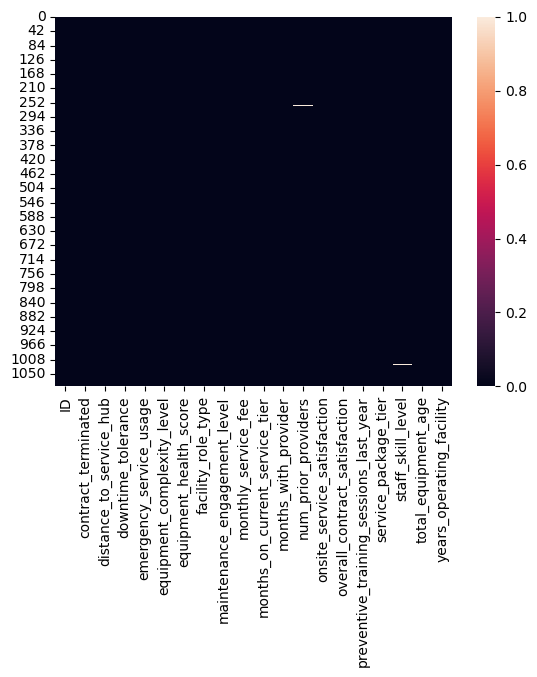

In [13]:
sns.heatmap(data_train.isna())

<Axes: xlabel='contract_terminated', ylabel='count'>

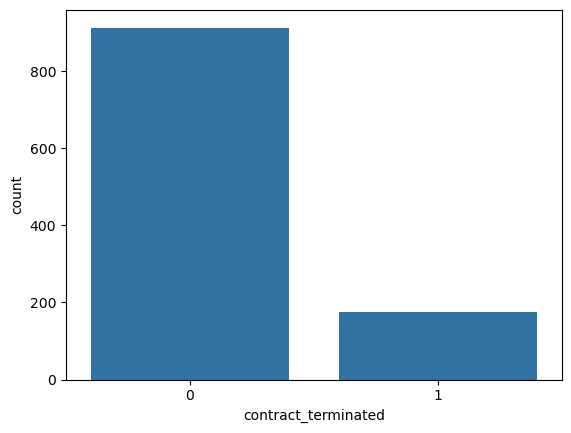

In [14]:
sns.countplot(x='contract_terminated', data=data_train)

## Истражување и визуелизација на test податоците

In [15]:
data_test.isna()

,ID,distance_to_service_hub,downtime_tolerance,emergency_service_usage,equipment_complexity_level,equipment_health_score,facility_role_type,maintenance_engagement_level,monthly_service_fee,months_on_current_service_tier,months_with_provider,num_prior_providers,onsite_service_satisfaction,overall_contract_satisfaction,preventive_training_sessions_last_year,service_package_tier,staff_skill_level,total_equipment_age,years_operating_facility
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
358,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
359,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
360,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
361,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


<Axes: >

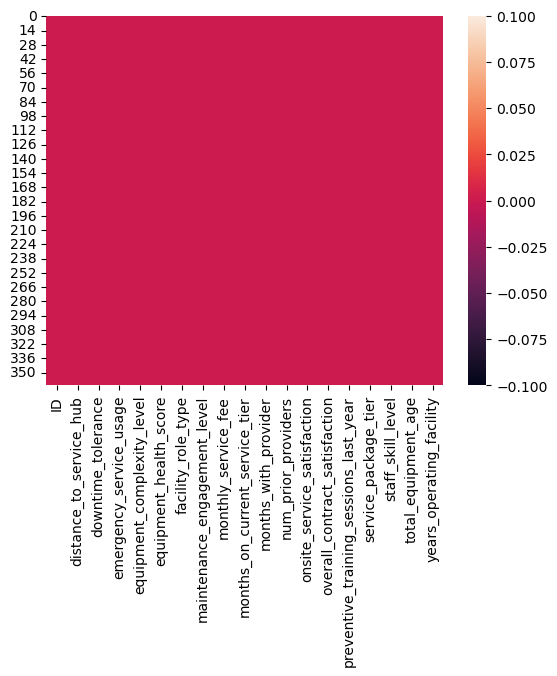

In [16]:
sns.heatmap(data_test.isna())

## Прочистување и оптимизација на train податоците

Поради малиот број на NaN вредности во табелата, може да се употреби методот на елиминација на редови со NaN вредности од податочното множество. Од кога ќе се направи тоа, може и да се податочниот тип на колоните за со цел да се заштеди на меморија и да се истренира моделот побрзо. 

In [17]:
data_train.dropna(inplace=True)

In [18]:
medians = data_train['num_prior_providers'].median()
medians

np.float64(2.0)

In [19]:
data_train['num_prior_providers'] = data_train['num_prior_providers'].replace(9999999, medians)

In [21]:
data_train['ID'] = data_train['ID'].astype(np.uint16)
data_train['contract_terminated'] = data_train['contract_terminated'].astype(np.uint8)
data_train['distance_to_service_hub'] = data_train['distance_to_service_hub'].astype(np.uint8)
data_train['downtime_tolerance'] = data_train['downtime_tolerance'].astype(np.uint8)
data_train['emergency_service_usage'] = data_train['emergency_service_usage'].astype(bool)
data_train['equipment_complexity_level'] = data_train['equipment_complexity_level'].astype(np.uint8)
data_train['equipment_health_score'] = data_train['equipment_health_score'].astype(np.uint8)
data_train['maintenance_engagement_level'] = data_train['maintenance_engagement_level'].astype(np.uint8)
data_train['monthly_service_fee'] = data_train['monthly_service_fee'].astype(np.int16)
data_train['months_on_current_service_tier'] = data_train['months_on_current_service_tier'].astype(np.uint8)
data_train['months_with_provider'] = data_train['months_with_provider'].astype(np.uint8)
data_train['num_prior_providers'] = data_train['num_prior_providers'].astype(np.uint8)
data_train['onsite_service_satisfaction'] = data_train['onsite_service_satisfaction'].astype(np.uint8)
data_train['overall_contract_satisfaction'] = data_train['overall_contract_satisfaction'].astype(np.uint8)
data_train['preventive_training_sessions_last_year'] = data_train['preventive_training_sessions_last_year'].astype(np.uint8)
data_train['staff_skill_level'] = data_train['staff_skill_level'].astype(np.uint8)
data_train['total_equipment_age'] = data_train['total_equipment_age'].astype(np.uint8)
data_train['years_operating_facility'] = data_train['years_operating_facility'].astype(np.uint8)

In [22]:
data_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1078 entries, 0 to 1086
Data columns (total 20 columns):
 #   Column                                  Non-Null Count  Dtype 
---  ------                                  --------------  ----- 
 0   ID                                      1078 non-null   uint16
 1   contract_terminated                     1078 non-null   uint8 
 2   distance_to_service_hub                 1078 non-null   uint8 
 3   downtime_tolerance                      1078 non-null   uint8 
 4   emergency_service_usage                 1078 non-null   bool  
 5   equipment_complexity_level              1078 non-null   uint8 
 6   equipment_health_score                  1078 non-null   uint8 
 7   facility_role_type                      1078 non-null   object
 8   maintenance_engagement_level            1078 non-null   uint8 
 9   monthly_service_fee                     1078 non-null   int16 
 10  months_on_current_service_tier          1078 non-null   uint8 
 11  months_wi

In [23]:
data_train.describe()

,ID,contract_terminated,distance_to_service_hub,downtime_tolerance,equipment_complexity_level,equipment_health_score,maintenance_engagement_level,monthly_service_fee,months_on_current_service_tier,months_with_provider,num_prior_providers,onsite_service_satisfaction,overall_contract_satisfaction,preventive_training_sessions_last_year,staff_skill_level,total_equipment_age,years_operating_facility
count,1078.000000,1078.000000,1078.000000,1078.000000,1078.000000,1078.000000,1078.000000,1078.000000,1078.000000,1078.000000,1078.000000,1078.000000,1078.000000,1078.000000,1078.000000,1078.000000,1078.000000
mean,543.855288,0.161410,9.204082,2.762523,2.075139,3.162338,2.726345,6584.574212,4.195733,7.026902,2.712430,2.715213,2.737477,2.804267,2.917440,22.328386,23.077922
std,313.066603,0.368079,8.107741,0.699652,1.119969,0.368931,0.706957,4794.562718,3.634624,6.210799,2.499926,1.094245,1.110725,1.272413,1.035871,7.705932,9.091174
min,1.000000,0.000000,1.000000,1.000000,1.000000,3.000000,1.000000,-299.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,11.000000,4.000000
25%,274.250000,0.000000,2.000000,2.000000,1.000000,3.000000,2.000000,2911.000000,2.000000,3.000000,1.000000,2.000000,2.000000,2.000000,2.000000,17.000000,17.000000
50%,544.500000,0.000000,7.000000,3.000000,2.000000,3.000000,3.000000,4988.000000,3.000000,5.000000,2.000000,3.000000,3.000000,3.000000,3.000000,21.000000,22.000000
75%,813.750000,0.000000,14.000000,3.000000,3.000000,3.000000,3.000000,8631.750000,7.000000,10.000000,4.000000,4.000000,4.000000,3.000000,4.000000,26.000000,29.000000
max,1087.000000,1.000000,29.000000,4.000000,5.000000,4.000000,4.000000,19943.000000,18.000000,40.000000,9.000000,4.000000,4.000000,6.000000,5.000000,51.000000,46.000000


#### Употреба на One-hot encoding на колоните facility_role_type и service_package_tier

In [24]:
data_train['service_package_tier'].unique()

array(['Silver', 'Bronze', 'Gold', 'Enterprise'], dtype=object)

In [25]:
data_train = pd.concat([data_train, pd.get_dummies(data_train['service_package_tier'], prefix='spt', drop_first=True)], axis=1)

In [26]:
data_train.drop(columns=['service_package_tier'], inplace = True)
data_train

,ID,contract_terminated,distance_to_service_hub,downtime_tolerance,emergency_service_usage,equipment_complexity_level,equipment_health_score,facility_role_type,maintenance_engagement_level,monthly_service_fee,...,num_prior_providers,onsite_service_satisfaction,overall_contract_satisfaction,preventive_training_sessions_last_year,staff_skill_level,total_equipment_age,years_operating_facility,spt_Enterprise,spt_Gold,spt_Silver
0,1,0,3,3,True,1,3,PrecisionManufacturing,2,2177,...,3,3,4,6,3,18,45,False,False,True
1,2,0,3,3,True,2,4,PharmaceuticalProduction,4,6842,...,6,4,1,3,2,24,22,False,False,True
2,3,0,8,3,True,2,3,HeavyIndustrialProcessing,3,5121,...,3,2,1,3,5,18,20,False,False,True
3,4,0,8,3,True,3,3,AdvancedAutomationCenter,2,13757,...,2,4,2,5,1,27,26,False,False,True
4,5,1,9,3,True,1,3,PackagingAndFinishing,2,4400,...,3,1,1,2,2,17,11,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1082,1083,0,26,3,True,5,4,LogisticsAndDistribution,2,19586,...,1,3,4,3,5,47,41,False,False,True
1083,1084,0,11,3,True,4,4,LogisticsAndDistribution,3,16032,...,3,2,4,2,4,37,40,False,False,True
1084,1085,0,14,3,True,1,3,PrecisionManufacturing,3,2451,...,4,1,3,2,3,24,27,False,False,True
1085,1086,1,10,4,True,1,4,PrecisionManufacturing,2,1859,...,1,1,2,2,3,12,5,False,False,False


In [27]:
data_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1078 entries, 0 to 1086
Data columns (total 22 columns):
 #   Column                                  Non-Null Count  Dtype 
---  ------                                  --------------  ----- 
 0   ID                                      1078 non-null   uint16
 1   contract_terminated                     1078 non-null   uint8 
 2   distance_to_service_hub                 1078 non-null   uint8 
 3   downtime_tolerance                      1078 non-null   uint8 
 4   emergency_service_usage                 1078 non-null   bool  
 5   equipment_complexity_level              1078 non-null   uint8 
 6   equipment_health_score                  1078 non-null   uint8 
 7   facility_role_type                      1078 non-null   object
 8   maintenance_engagement_level            1078 non-null   uint8 
 9   monthly_service_fee                     1078 non-null   int16 
 10  months_on_current_service_tier          1078 non-null   uint8 
 11  months_wi

In [28]:
data_train['facility_role_type'].unique()

array(['PrecisionManufacturing', 'PharmaceuticalProduction',
       'HeavyIndustrialProcessing', 'AdvancedAutomationCenter',
       'PackagingAndFinishing', 'LogisticsAndDistribution',
       'TestingAndCalibration', 'AssemblyFacility', 'Other'], dtype=object)

In [29]:
data_train = pd.concat([data_train, pd.get_dummies(data_train['facility_role_type'], prefix='frt', drop_first=True)], axis=1)

In [30]:
data_train.drop(columns=['facility_role_type'], inplace = True)
data_train

,ID,contract_terminated,distance_to_service_hub,downtime_tolerance,emergency_service_usage,equipment_complexity_level,equipment_health_score,maintenance_engagement_level,monthly_service_fee,months_on_current_service_tier,...,spt_Gold,spt_Silver,frt_AssemblyFacility,frt_HeavyIndustrialProcessing,frt_LogisticsAndDistribution,frt_Other,frt_PackagingAndFinishing,frt_PharmaceuticalProduction,frt_PrecisionManufacturing,frt_TestingAndCalibration
0,1,0,3,3,True,1,3,2,2177,0,...,False,True,False,False,False,False,False,False,True,False
1,2,0,3,3,True,2,4,4,6842,4,...,False,True,False,False,False,False,False,True,False,False
2,3,0,8,3,True,2,3,3,5121,0,...,False,True,False,True,False,False,False,False,False,False
3,4,0,8,3,True,3,3,2,13757,8,...,False,True,False,False,False,False,False,False,False,False
4,5,1,9,3,True,1,3,2,4400,2,...,False,False,False,False,False,False,True,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1082,1083,0,26,3,True,5,4,2,19586,6,...,False,True,False,False,True,False,False,False,False,False
1083,1084,0,11,3,True,4,4,3,16032,9,...,False,True,False,False,True,False,False,False,False,False
1084,1085,0,14,3,True,1,3,3,2451,8,...,False,True,False,False,False,False,False,False,True,False
1085,1086,1,10,4,True,1,4,2,1859,1,...,False,False,False,False,False,False,False,False,True,False


In [31]:
data_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1078 entries, 0 to 1086
Data columns (total 29 columns):
 #   Column                                  Non-Null Count  Dtype 
---  ------                                  --------------  ----- 
 0   ID                                      1078 non-null   uint16
 1   contract_terminated                     1078 non-null   uint8 
 2   distance_to_service_hub                 1078 non-null   uint8 
 3   downtime_tolerance                      1078 non-null   uint8 
 4   emergency_service_usage                 1078 non-null   bool  
 5   equipment_complexity_level              1078 non-null   uint8 
 6   equipment_health_score                  1078 non-null   uint8 
 7   maintenance_engagement_level            1078 non-null   uint8 
 8   monthly_service_fee                     1078 non-null   int16 
 9   months_on_current_service_tier          1078 non-null   uint8 
 10  months_with_provider                    1078 non-null   uint8 
 11  num_prior

## Прочистување и оптимизирање на test податоците

In [32]:
medians = data_test['num_prior_providers'].median()
medians

np.float64(1.0)

In [33]:
data_test['months_with_provider'] = data_test['months_with_provider'].replace(9999999, medians)

In [34]:
data_test.describe()

,ID,distance_to_service_hub,downtime_tolerance,equipment_complexity_level,equipment_health_score,maintenance_engagement_level,monthly_service_fee,months_on_current_service_tier,months_with_provider,num_prior_providers,onsite_service_satisfaction,overall_contract_satisfaction,preventive_training_sessions_last_year,staff_skill_level,total_equipment_age,years_operating_facility
count,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000
mean,182.000000,9.082645,2.768595,2.022039,3.134986,2.741047,6214.371901,4.347107,6.906336,2.630854,2.765840,2.710744,2.807163,2.892562,21.994490,22.435262
std,104.933312,8.092613,0.729342,1.066600,0.342181,0.727628,4481.525948,3.623993,5.872216,2.514343,1.088737,1.075375,1.354858,0.992805,7.897127,9.299086
min,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000,1052.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,11.000000,4.000000
25%,91.500000,2.000000,2.000000,1.000000,3.000000,2.000000,2922.500000,2.000000,3.000000,1.000000,2.000000,2.000000,2.000000,2.000000,17.000000,15.000000
50%,182.000000,7.000000,3.000000,2.000000,3.000000,3.000000,4663.000000,3.000000,5.000000,1.000000,3.000000,3.000000,3.000000,3.000000,20.000000,21.000000
75%,272.500000,13.000000,3.000000,3.000000,3.000000,3.000000,7497.000000,7.000000,9.000000,4.000000,4.000000,4.000000,3.000000,4.000000,25.000000,29.000000
max,363.000000,29.000000,4.000000,5.000000,4.000000,4.000000,19999.000000,18.000000,33.000000,9.000000,4.000000,4.000000,6.000000,5.000000,48.000000,45.000000


In [35]:
data_test['ID'] = data_test['ID'].astype(np.uint16)
data_test['distance_to_service_hub'] = data_test['distance_to_service_hub'].astype(np.uint8)
data_test['downtime_tolerance'] = data_test['downtime_tolerance'].astype(np.uint8)
data_test['emergency_service_usage'] = data_test['emergency_service_usage'].astype(bool)
data_test['equipment_complexity_level'] = data_test['equipment_complexity_level'].astype(np.uint8)
data_test['equipment_health_score'] = data_test['equipment_health_score'].astype(np.uint8)
data_test['maintenance_engagement_level'] = data_test['maintenance_engagement_level'].astype(np.uint8)
data_test['monthly_service_fee'] = data_test['monthly_service_fee'].astype(np.int16)
data_test['months_on_current_service_tier'] = data_test['months_on_current_service_tier'].astype(np.uint8)
data_test['months_with_provider'] = data_test['months_with_provider'].astype(np.uint8)
data_test['num_prior_providers'] = data_test['num_prior_providers'].astype(np.uint8)
data_test['onsite_service_satisfaction'] = data_test['onsite_service_satisfaction'].astype(np.uint8)
data_test['overall_contract_satisfaction'] = data_test['overall_contract_satisfaction'].astype(np.uint8)
data_test['preventive_training_sessions_last_year'] = data_test['preventive_training_sessions_last_year'].astype(np.uint8)
data_test['staff_skill_level'] = data_test['staff_skill_level'].astype(np.uint8)
data_test['total_equipment_age'] = data_test['total_equipment_age'].astype(np.uint8)
data_test['years_operating_facility'] = data_test['years_operating_facility'].astype(np.uint8)

In [36]:
data_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 363 entries, 0 to 362
Data columns (total 19 columns):
 #   Column                                  Non-Null Count  Dtype 
---  ------                                  --------------  ----- 
 0   ID                                      363 non-null    uint16
 1   distance_to_service_hub                 363 non-null    uint8 
 2   downtime_tolerance                      363 non-null    uint8 
 3   emergency_service_usage                 363 non-null    bool  
 4   equipment_complexity_level              363 non-null    uint8 
 5   equipment_health_score                  363 non-null    uint8 
 6   facility_role_type                      363 non-null    object
 7   maintenance_engagement_level            363 non-null    uint8 
 8   monthly_service_fee                     363 non-null    int16 
 9   months_on_current_service_tier          363 non-null    uint8 
 10  months_with_provider                    363 non-null    uint8 
 11  num_pr

In [37]:
data_test.describe()

,ID,distance_to_service_hub,downtime_tolerance,equipment_complexity_level,equipment_health_score,maintenance_engagement_level,monthly_service_fee,months_on_current_service_tier,months_with_provider,num_prior_providers,onsite_service_satisfaction,overall_contract_satisfaction,preventive_training_sessions_last_year,staff_skill_level,total_equipment_age,years_operating_facility
count,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000,363.000000
mean,182.000000,9.082645,2.768595,2.022039,3.134986,2.741047,6214.371901,4.347107,6.906336,2.630854,2.765840,2.710744,2.807163,2.892562,21.994490,22.435262
std,104.933312,8.092613,0.729342,1.066600,0.342181,0.727628,4481.525948,3.623993,5.872216,2.514343,1.088737,1.075375,1.354858,0.992805,7.897127,9.299086
min,1.000000,1.000000,1.000000,1.000000,3.000000,1.000000,1052.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,11.000000,4.000000
25%,91.500000,2.000000,2.000000,1.000000,3.000000,2.000000,2922.500000,2.000000,3.000000,1.000000,2.000000,2.000000,2.000000,2.000000,17.000000,15.000000
50%,182.000000,7.000000,3.000000,2.000000,3.000000,3.000000,4663.000000,3.000000,5.000000,1.000000,3.000000,3.000000,3.000000,3.000000,20.000000,21.000000
75%,272.500000,13.000000,3.000000,3.000000,3.000000,3.000000,7497.000000,7.000000,9.000000,4.000000,4.000000,4.000000,3.000000,4.000000,25.000000,29.000000
max,363.000000,29.000000,4.000000,5.000000,4.000000,4.000000,19999.000000,18.000000,33.000000,9.000000,4.000000,4.000000,6.000000,5.000000,48.000000,45.000000


#### Употреба на One-hot encoding на колоните facility_role_type и service_package_tier

In [38]:
data_test['service_package_tier'].unique()

array(['Bronze', 'Enterprise', 'Silver', 'Gold'], dtype=object)

In [39]:
data_test = pd.concat([data_test, pd.get_dummies(data_test['service_package_tier'], prefix='spt', drop_first=True)], axis=1)

In [40]:
data_test.drop(columns=['service_package_tier'], inplace = True)
data_test

,ID,distance_to_service_hub,downtime_tolerance,emergency_service_usage,equipment_complexity_level,equipment_health_score,facility_role_type,maintenance_engagement_level,monthly_service_fee,months_on_current_service_tier,...,num_prior_providers,onsite_service_satisfaction,overall_contract_satisfaction,preventive_training_sessions_last_year,staff_skill_level,total_equipment_age,years_operating_facility,spt_Enterprise,spt_Gold,spt_Silver
0,1,2,3,True,1,3,PrecisionManufacturing,2,4968,7,...,0,4,1,2,4,21,16,False,False,False
1,2,29,4,True,1,3,TestingAndCalibration,3,3907,2,...,1,2,1,2,1,17,10,True,False,False
2,3,1,4,True,1,4,Other,3,2064,3,...,0,3,3,3,3,17,16,False,False,True
3,4,26,3,True,2,3,AssemblyFacility,2,7991,2,...,8,2,2,3,2,17,32,False,False,False
4,5,4,3,True,2,3,AssemblyFacility,2,5828,7,...,1,4,4,0,4,19,12,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
358,359,2,3,True,2,3,AssemblyFacility,3,5677,8,...,3,2,2,4,2,26,26,False,False,True
359,360,17,2,True,1,3,Other,3,2741,7,...,0,2,3,2,4,19,12,False,False,True
360,361,1,2,True,1,3,TestingAndCalibration,3,3229,2,...,4,1,4,2,3,18,11,False,False,True
361,362,9,2,True,2,3,TestingAndCalibration,3,5346,1,...,4,4,1,3,4,22,20,False,False,True


In [41]:
data_test['facility_role_type'].unique()

array(['PrecisionManufacturing', 'TestingAndCalibration', 'Other',
       'AssemblyFacility', 'LogisticsAndDistribution',
       'AdvancedAutomationCenter', 'HeavyIndustrialProcessing',
       'PharmaceuticalProduction', 'PackagingAndFinishing'], dtype=object)

In [42]:
data_test = pd.concat([data_test, pd.get_dummies(data_test['facility_role_type'], prefix='frt', drop_first=True)], axis=1)

In [43]:
data_test.drop(columns=['facility_role_type'], inplace = True)
data_test

,ID,distance_to_service_hub,downtime_tolerance,emergency_service_usage,equipment_complexity_level,equipment_health_score,maintenance_engagement_level,monthly_service_fee,months_on_current_service_tier,months_with_provider,...,spt_Gold,spt_Silver,frt_AssemblyFacility,frt_HeavyIndustrialProcessing,frt_LogisticsAndDistribution,frt_Other,frt_PackagingAndFinishing,frt_PharmaceuticalProduction,frt_PrecisionManufacturing,frt_TestingAndCalibration
0,1,2,3,True,1,3,2,4968,7,9,...,False,False,False,False,False,False,False,False,True,False
1,2,29,4,True,1,3,3,3907,2,6,...,False,False,False,False,False,False,False,False,False,True
2,3,1,4,True,1,4,3,2064,3,5,...,False,True,False,False,False,True,False,False,False,False
3,4,26,3,True,2,3,2,7991,2,2,...,False,False,True,False,False,False,False,False,False,False
4,5,4,3,True,2,3,2,5828,7,8,...,False,False,True,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
358,359,2,3,True,2,3,3,5677,8,11,...,False,True,True,False,False,False,False,False,False,False
359,360,17,2,True,1,3,3,2741,7,7,...,False,True,False,False,False,True,False,False,False,False
360,361,1,2,True,1,3,3,3229,2,3,...,False,True,False,False,False,False,False,False,False,True
361,362,9,2,True,2,3,3,5346,1,7,...,False,True,False,False,False,False,False,False,False,True


## Градење на модел на логистичка регресија

In [44]:
X_train = data_train.drop(columns=['contract_terminated'])
y_train = data_train['contract_terminated']

In [45]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)

In [46]:
model = LogisticRegression(tol=1e-10, C=0.05, fit_intercept=True, max_iter=1000000, n_jobs=-1, solver='lbfgs', class_weight='balanced')

In [47]:
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,1e-10
,C,0.05
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,1000000
,multi_class,'deprecated'


In [48]:
model.n_iter_, model.coef_

(array([29], dtype=int32),
 array([[-0.15785609,  0.30696901, -0.13106103,  0.        , -0.15100446,
         -0.03740332, -0.28281471, -0.06250379, -0.43672666,  0.44862667,
          0.24203195, -0.29549497, -0.30013083, -0.22864341,  0.03216856,
         -0.2018821 , -0.24999965, -0.08002281, -0.3637468 , -0.50835764,
          0.22945693,  0.01386528, -0.00183645,  0.03202409,  0.24208187,
         -0.05655093, -0.01702526,  0.22057197]]))

In [49]:
model.score(X_train, y_train)

0.738404452690167

## F1 метрика (F1 score)

In [52]:
X_test_scaled = scaler.transform(X_train)

In [53]:
y_predicted = model.predict(X_test_scaled)
y_predicted

array([0, 0, 0, ..., 0, 1, 0], dtype=uint8)

In [54]:
confusion_matrix(y_test, y_predicted)


ValueError: Found input variables with inconsistent numbers of samples: [363, 1078]

In [142]:
print(classification_report(y_predicted, y_test))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00       0.0
           1       0.00      0.00      0.00     363.0

    accuracy                           0.00     363.0
   macro avg       0.00      0.00      0.00     363.0
weighted avg       0.00      0.00      0.00     363.0



/home/rademicov/.var/app/org.jupyter.JupyterLab/config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/rademicov/.var/app/org.jupyter.JupyterLab/config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/rademicov/.var/app/org.jupyter.JupyterLab/config/jupyterlab-desktop/jlab_server/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being s

In [143]:
y_predicted

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,

In [144]:
pd.DataFrame(y_predicted, columns=["contract_terminated"]).to_csv("predictions.csv", index=False)

In [145]:
df = pd.read_csv('predictions_wo.csv')
df.insert(0, "ID", range(1, len(df)+1))
pd.DataFrame(df, columns=["ID","contract_terminated"]).to_csv("predictions.csv", index=False)

In [146]:
df.head()

,ID,contract_terminated
0,1,1
1,2,1
2,3,0
3,4,1
4,5,1


In [147]:
pd.DataFrame(y_predicted, columns=["contract_terminated"]).to_csv("predictions_wo.csv", index=False)

In [1]:
y_predicted_test = model.predict(X_test_scaled)

NameError: name 'model' is not defined